# Few-Shot Learning — B10/N10 Results

**Split:** 10 base / 10 novel | **Protocol:** 5-way K-shot (5 of 10 novel sampled), 600 episodes

**Backbones:** ResNet-50 · DeiT-S | **Methods:** NCC · ProtoNet · MatchingNet · MatchingNet+FCE · RelationNet · ProtoNet+TTA

**Novel (10):** ALBERTS TOWHEE, ALEXANDRINE PARAKEET, ALPINE CHOUGH, ALTAMIRA YELLOWTHROAT, AMERICAN AVOCET,
AMERICAN BITTERN, AMERICAN COOT, AMERICAN FLAMINGO, AMERICAN GOLDFINCH, AMERICAN KESTREL

In [1]:

%matplotlib inline
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=120; plt.rcParams['savefig.dpi']=150
plt.rcParams['figure.facecolor']='white'; plt.rcParams['axes.facecolor']='white'

NB_DIR=os.getcwd()
ROOT=os.path.normpath(os.path.join(NB_DIR,'..'))
RES=os.path.join(ROOT,'results')
ANALYSIS=os.path.join(RES,'analysis')
os.makedirs(ANALYSIS,exist_ok=True)

PATHS={
    'base10_json'               :f'{RES}/baseline/resnet50/base10/base_test/summary.json',
    'kshot5_b10_json'           :f'{RES}/baseline/resnet50/base10/novel_kshot_5/summary.json',
    'ncc_1shot_euc_json'        :f'{RES}/baseline/resnet50/base10/novel_ncc/1shot_euclidean/summary.json',
    'ncc_1shot_man_json'        :f'{RES}/baseline/resnet50/base10/novel_ncc/1shot_manhattan/summary.json',
    'ncc_3shot_euc_json'        :f'{RES}/baseline/resnet50/base10/novel_ncc/3shot_euclidean/summary.json',
    'ncc_3shot_man_json'        :f'{RES}/baseline/resnet50/base10/novel_ncc/3shot_manhattan/summary.json',
    'ncc_5shot_euc_json'        :f'{RES}/baseline/resnet50/base10/novel_ncc/5shot_euclidean/summary.json',
    'ncc_5shot_man_json'        :f'{RES}/baseline/resnet50/base10/novel_ncc/5shot_manhattan/summary.json',
    'proto_1shot_euc_json'      :f'{RES}/proto_net/base10_novel10/1shot_euclidean/summary.json',
    'proto_1shot_man_json'      :f'{RES}/proto_net/base10_novel10/1shot_manhattan/summary.json',
    'proto_3shot_euc_json'      :f'{RES}/proto_net/base10_novel10/3shot_euclidean/summary.json',
    'proto_3shot_man_json'      :f'{RES}/proto_net/base10_novel10/3shot_manhattan/summary.json',
    'proto_5shot_euc_json'      :f'{RES}/proto_net/base10_novel10/5shot_euclidean/summary.json',
    'proto_5shot_man_json'      :f'{RES}/proto_net/base10_novel10/5shot_manhattan/summary.json',
    'proto_5shot_euc_tta8_json' :f'{RES}/proto_net/base10_novel10/5shot_euclidean_tta8/summary.json',
    'match_1shot_json'          :f'{RES}/matching_net/base10_novel10/1shot/summary.json',
    'match_3shot_json'          :f'{RES}/matching_net/base10_novel10/3shot/summary.json',
    'match_5shot_json'          :f'{RES}/matching_net/base10_novel10/5shot/summary.json',
    'match_fce_1shot_json'      :f'{RES}/matching_net_fce/base10_novel10/1shot/summary.json',
    'match_fce_3shot_json'      :f'{RES}/matching_net_fce/base10_novel10/3shot/summary.json',
    'match_fce_5shot_json'      :f'{RES}/matching_net_fce/base10_novel10/5shot/summary.json',
    'rel_1shot_json'            :f'{RES}/relation_net/base10_novel10/1shot/summary.json',
    'rel_3shot_json'            :f'{RES}/relation_net/base10_novel10/3shot/summary.json',
    'rel_5shot_json'            :f'{RES}/relation_net/base10_novel10/5shot/summary.json',
    'vit_ncc_1shot_euc_json'    :f'{RES}/vit/baseline/base10/novel_ncc/1shot_euclidean/summary.json',
    'vit_ncc_1shot_man_json'    :f'{RES}/vit/baseline/base10/novel_ncc/1shot_manhattan/summary.json',
    'vit_ncc_3shot_euc_json'    :f'{RES}/vit/baseline/base10/novel_ncc/3shot_euclidean/summary.json',
    'vit_ncc_3shot_man_json'    :f'{RES}/vit/baseline/base10/novel_ncc/3shot_manhattan/summary.json',
    'vit_ncc_5shot_euc_json'    :f'{RES}/vit/baseline/base10/novel_ncc/5shot_euclidean/summary.json',
    'vit_ncc_5shot_man_json'    :f'{RES}/vit/baseline/base10/novel_ncc/5shot_manhattan/summary.json',
    'vit_proto_1shot_euc_json'  :f'{RES}/vit/proto_net/base10_novel10/1shot_euclidean/summary.json',
    'vit_proto_1shot_man_json'  :f'{RES}/vit/proto_net/base10_novel10/1shot_manhattan/summary.json',
    'vit_proto_3shot_euc_json'  :f'{RES}/vit/proto_net/base10_novel10/3shot_euclidean/summary.json',
    'vit_proto_3shot_man_json'  :f'{RES}/vit/proto_net/base10_novel10/3shot_manhattan/summary.json',
    'vit_proto_5shot_euc_json'  :f'{RES}/vit/proto_net/base10_novel10/5shot_euclidean/summary.json',
    'vit_proto_5shot_man_json'  :f'{RES}/vit/proto_net/base10_novel10/5shot_manhattan/summary.json',
}

R={}
for k,p in PATHS.items():
    if os.path.exists(p):
        with open(p) as f: R[k]=json.load(f)
    else:
        R[k]=None; print(f'  [missing] {k}')
present=sum(1 for v in R.values() if v is not None)
print(f'Loaded {present}/{len(R)} files.')

def acc(k): return float(R[k]['mean_accuracy_pct']) if R.get(k) else float('nan')
def ci(k):  return float(R[k]['ci95_pct'])          if R.get(k) else 0.0
def f1(k):  return float(R[k]['macro_f1'])          if R.get(k) and R[k].get('macro_f1') else float('nan')
SHOTS=[1,3,5]
NOVEL=['ALBERTS TOWHEE','ALEXANDRINE PARAKEET','ALPINE CHOUGH','ALTAMIRA YELLOWTHROAT',
       'AMERICAN AVOCET','AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO',
       'AMERICAN GOLDFINCH','AMERICAN KESTREL']
SHORT=[c.replace('AMERICAN ','AM.').replace('ALEXANDRINE ','ALEX.').replace('ALTAMIRA ','ALTA.').replace('ALBERTS ','ALB.').replace('ALPINE ','ALP.') for c in NOVEL]


Loaded 36/36 files.


---
## 1. Supervised Baselines (Reference)

In [2]:

for label,key,note in [('Base-10 Supervised','base10_json','Base-class eval'),
                        ('K=5 Fine-tune (novel)','kshot5_b10_json','Novel 5-shot finetune')]:
    d=R.get(key)
    if not d: print(f'{label}: [missing]'); continue
    a=float(d.get('accuracy',d.get('test_accuracy',0)))*100
    fm=d.get('macro_f1')
    print(f'{label:<30} acc={a:.2f}%  | {note}')


Base-10 Supervised             acc=100.00%  | Base-class eval
K=5 Fine-tune (novel)          acc=92.00%  | Novel 5-shot finetune


---
## 2. NCC: ResNet-50 vs DeiT-S (B10/N10)

,Model,K-Shot,Accuracy(%),95% CI,F1
0,NCC/R50 (Euc),1,87.01,+-0.81,0.8703
1,NCC/R50 (Man),1,76.28,+-0.99,0.7654
2,NCC/DeiT-S (Euc),1,95.35,+-0.49,0.9534
3,NCC/DeiT-S (Man),1,95.42,+-0.48,0.9541
4,NCC/R50 (Euc),3,96.20,+-0.41,0.9620
5,NCC/R50 (Man),3,90.25,+-0.61,0.9030
6,NCC/DeiT-S (Euc),3,98.11,+-0.25,0.9811
7,NCC/DeiT-S (Man),3,98.13,+-0.25,0.9813
8,NCC/R50 (Euc),5,97.40,+-0.33,0.9740
9,NCC/R50 (Man),5,92.90,+-0.52,0.9294


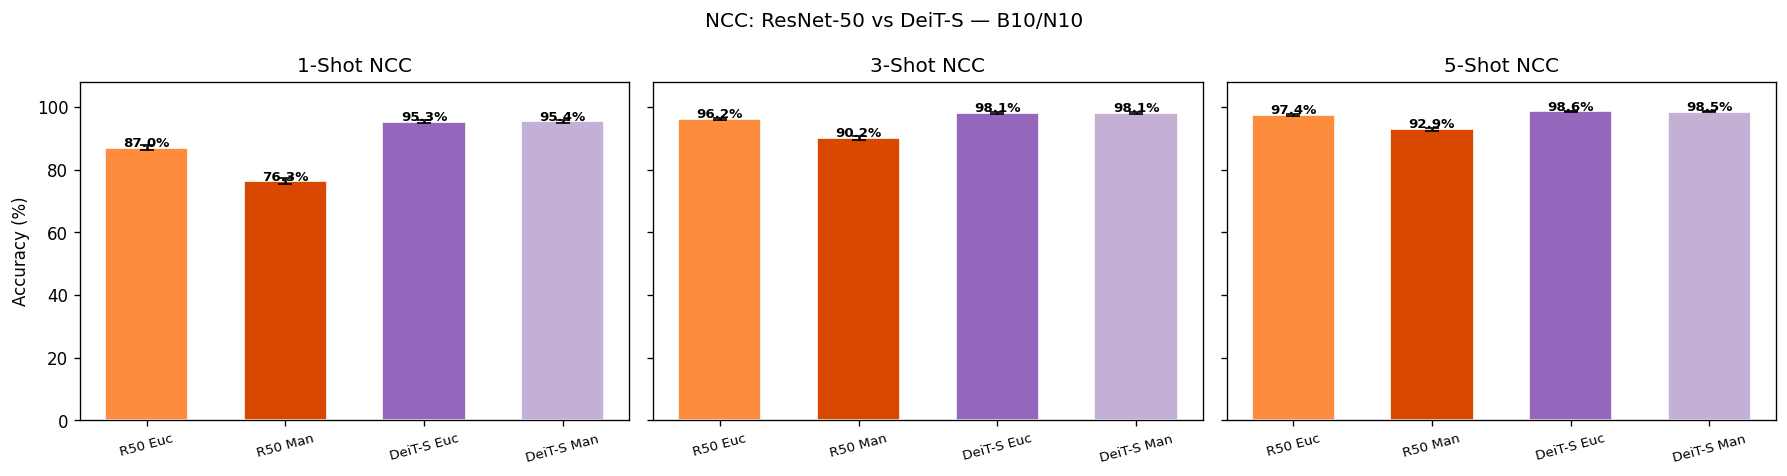

In [3]:

rows=[]
for s in SHOTS:
    for label,tmpl in [('NCC/R50 (Euc)','ncc_{s}shot_euc_json'),('NCC/R50 (Man)','ncc_{s}shot_man_json'),
                        ('NCC/DeiT-S (Euc)','vit_ncc_{s}shot_euc_json'),('NCC/DeiT-S (Man)','vit_ncc_{s}shot_man_json')]:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Model':label,'K-Shot':s,'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—','F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—'})
display(pd.DataFrame(rows))
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,shot in zip(axes,SHOTS):
    cfgs=[('R50 Euc',f'ncc_{shot}shot_euc_json','#fd8d3c'),('R50 Man',f'ncc_{shot}shot_man_json','#d94801'),
           ('DeiT-S Euc',f'vit_ncc_{shot}shot_euc_json','#9467bd'),('DeiT-S Man',f'vit_ncc_{shot}shot_man_json','#c5b0d5')]
    ls=[c[0] for c in cfgs]; vs=[acc(c[1]) for c in cfgs]; es=[ci(c[1]) for c in cfgs]; cs=[c[2] for c in cfgs]
    bars=ax.bar(ls,vs,color=cs,edgecolor='white',width=0.6)
    ax.errorbar(range(len(ls)),vs,yerr=es,fmt='none',color='black',capsize=4)
    for bar,v in zip(bars,vs): ax.text(bar.get_x()+bar.get_width()/2,v+0.4,f'{v:.1f}%',ha='center',fontsize=8,fontweight='bold')
    ax.set_title(f'{shot}-Shot NCC'); ax.set_ylim(0,108)
    ax.set_ylabel('Accuracy (%)' if shot==1 else ''); ax.tick_params(axis='x',labelrotation=15,labelsize=8)
fig.suptitle('NCC: ResNet-50 vs DeiT-S — B10/N10',fontsize=12)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b10n10_ncc_r50_vs_deit.png',dpi=150); plt.show()


---
## 3. ProtoNet: ResNet-50 vs DeiT-S (B10/N10)

In [4]:

rows=[]
for s in SHOTS:
    for label,tmpl in [('ProtoNet/R50 (Euc)','proto_{s}shot_euc_json'),('ProtoNet/R50 (Man)','proto_{s}shot_man_json'),
                        ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json'),('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json')]:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Model':label,'K-Shot':s,'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—','F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—'})
display(pd.DataFrame(rows))


,Model,K-Shot,Accuracy(%),95% CI,F1
0,ProtoNet/R50 (Euc),1,88.45,+-0.80,0.8842
1,ProtoNet/R50 (Man),1,76.10,+-1.00,0.7626
2,ProtoNet/DeiT-S (Euc),1,94.47,+-0.52,0.9447
3,ProtoNet/DeiT-S (Man),1,94.40,+-0.50,0.9440
4,ProtoNet/R50 (Euc),3,94.83,+-0.49,0.9485
5,ProtoNet/R50 (Man),3,87.64,+-0.73,0.8769
6,ProtoNet/DeiT-S (Euc),3,97.17,+-0.31,0.9718
7,ProtoNet/DeiT-S (Man),3,97.17,+-0.30,0.9718
8,ProtoNet/R50 (Euc),5,95.77,+-0.41,0.9580
9,ProtoNet/R50 (Man),5,90.14,+-0.64,0.9017


---
## 4. MatchingNet: Vanilla vs FCE (B10/N10)

FCE adds BiLSTM support encoding + attention LSTM query encoding.

In [5]:

rows=[]
for s in SHOTS:
    for label,tmpl in [('MatchingNet (vanilla)','match_{s}shot_json'),('MatchingNet+FCE','match_fce_{s}shot_json')]:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Model':label,'K-Shot':s,'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—','F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—'})
display(pd.DataFrame(rows))
deltas=[acc(f'match_fce_{s}shot_json')-acc(f'match_{s}shot_json') for s in SHOTS]
print('FCE effect: '+', '.join([f'{s}-shot: {d:+.2f}pp' for s,d in zip(SHOTS,deltas)]))


,Model,K-Shot,Accuracy(%),95% CI,F1
0,MatchingNet (vanilla),1,59.11,+-1.01,0.5920
1,MatchingNet+FCE,1,53.99,+-1.03,0.5300
2,MatchingNet (vanilla),3,63.35,+-0.95,0.6338
3,MatchingNet+FCE,3,56.85,+-0.99,0.5555
4,MatchingNet (vanilla),5,66.74,+-0.94,0.6667
5,MatchingNet+FCE,5,58.81,+-1.03,0.5731


FCE effect: 1-shot: -5.11pp, 3-shot: -6.50pp, 5-shot: -7.93pp


---
## 5. RelationNet (B10/N10)

In [6]:

print('RelationNet — B10/N10')
for s in SHOTS:
    k=f'rel_{s}shot_json'
    print(f'  {s}-shot: {acc(k):.2f}% +-{ci(k):.2f}  F1={f1(k):.4f}')


RelationNet — B10/N10
  1-shot: 56.41% +-1.12  F1=0.5650
  3-shot: 62.71% +-0.96  F1=0.6277
  5-shot: 65.71% +-0.88  F1=0.6569


---
## 6. ProtoNet + TTA (B10/N10)

In [7]:

base_a=acc('proto_5shot_euc_json'); tta_a=acc('proto_5shot_euc_tta8_json')
base_c=ci('proto_5shot_euc_json');  tta_c=ci('proto_5shot_euc_tta8_json')
print(f'Without TTA: {base_a:.2f}% +-{base_c:.2f}')
print(f'With TTA x8: {tta_a:.2f}% +-{tta_c:.2f}')
print(f'Delta: {tta_a-base_a:+.2f} pp')


Without TTA: 95.77% +-0.41
With TTA x8: 96.64% +-0.37
Delta: +0.87 pp


---
## 7. K-Shot Trend — All Methods (B10/N10)

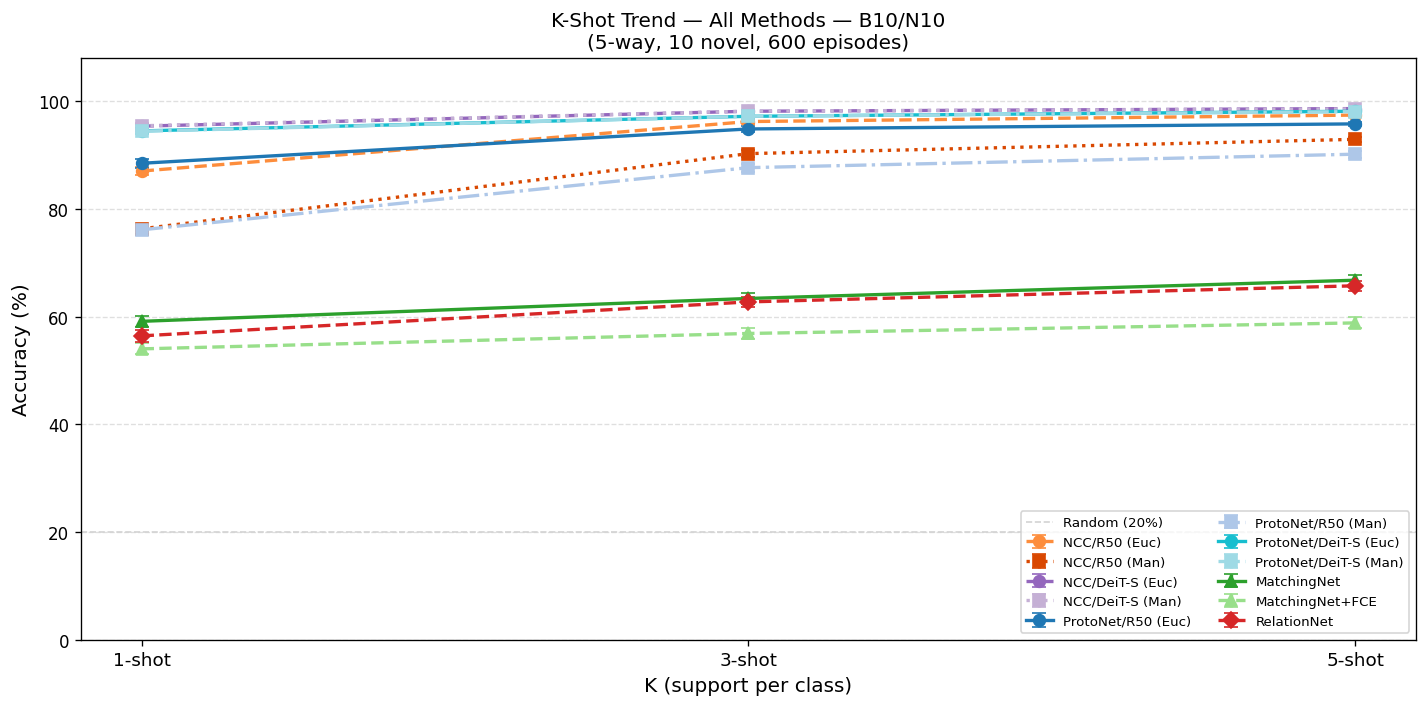

In [8]:

method_configs=[
    ('NCC/R50 (Euc)',         'ncc_{s}shot_euc_json',         '#fd8d3c','o','--'),
    ('NCC/R50 (Man)',         'ncc_{s}shot_man_json',         '#d94801','s',':'),
    ('NCC/DeiT-S (Euc)',      'vit_ncc_{s}shot_euc_json',     '#9467bd','o','--'),
    ('NCC/DeiT-S (Man)',      'vit_ncc_{s}shot_man_json',     '#c5b0d5','s',':'),
    ('ProtoNet/R50 (Euc)',    'proto_{s}shot_euc_json',       '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',    'proto_{s}shot_man_json',       '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json',   '#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json',   '#9edae5','s','-.'),
    ('MatchingNet',           'match_{s}shot_json',           '#2ca02c','^','-'),
    ('MatchingNet+FCE',       'match_fce_{s}shot_json',       '#98df8a','^','--'),
    ('RelationNet',           'rel_{s}shot_json',             '#d62728','D','--'),
]

fig,ax=plt.subplots(figsize=(12,6))
for label,tmpl,color,marker,ls in method_configs:
    xs,ys,es=[],[],[]
    for s in SHOTS:
        k=tmpl.format(s=s)
        if R.get(k): xs.append(s); ys.append(acc(k)); es.append(ci(k))
    if xs: ax.errorbar(xs,ys,yerr=es,label=label,color=color,marker=marker,linestyle=ls,linewidth=2,markersize=7,capsize=4)
ax.axhline(20,color='lightgray',linestyle='--',linewidth=1,label='Random (20%)')
ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS],fontsize=11)
ax.set_xlabel('K (support per class)',fontsize=12); ax.set_ylabel('Accuracy (%)',fontsize=12)
ax.set_ylim(0,108); ax.legend(loc='lower right',fontsize=8,ncol=2)
ax.grid(axis='y',linestyle='--',alpha=0.4)

ax.set_title('K-Shot Trend — All Methods — B10/N10\n(5-way, 10 novel, 600 episodes)')
ax.legend(loc='lower right',fontsize=8,ncol=2)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b10n10_kshot_all.png',dpi=150); plt.show()


---
## 8. Per-Class Accuracy Heatmap (B10/N10)

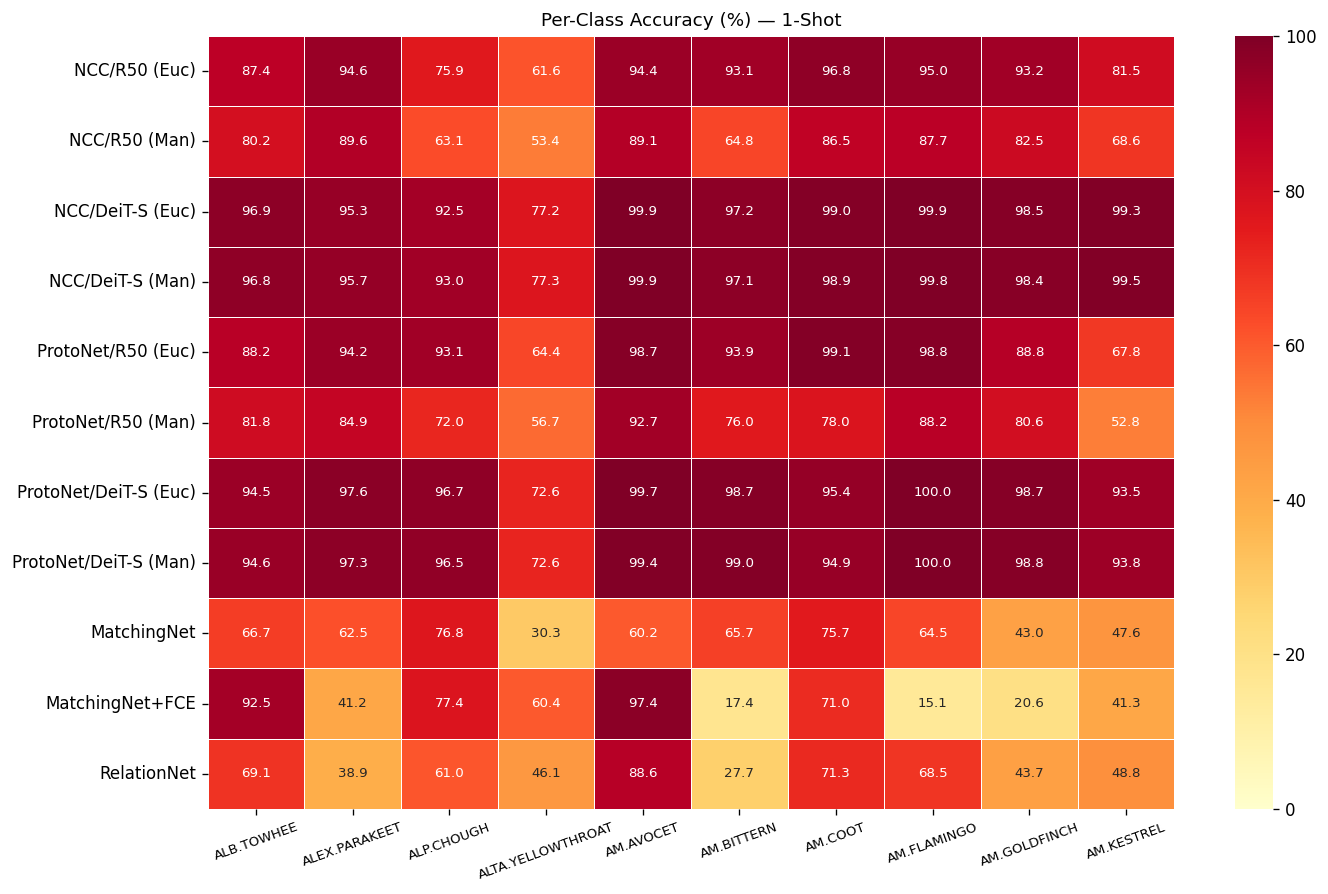

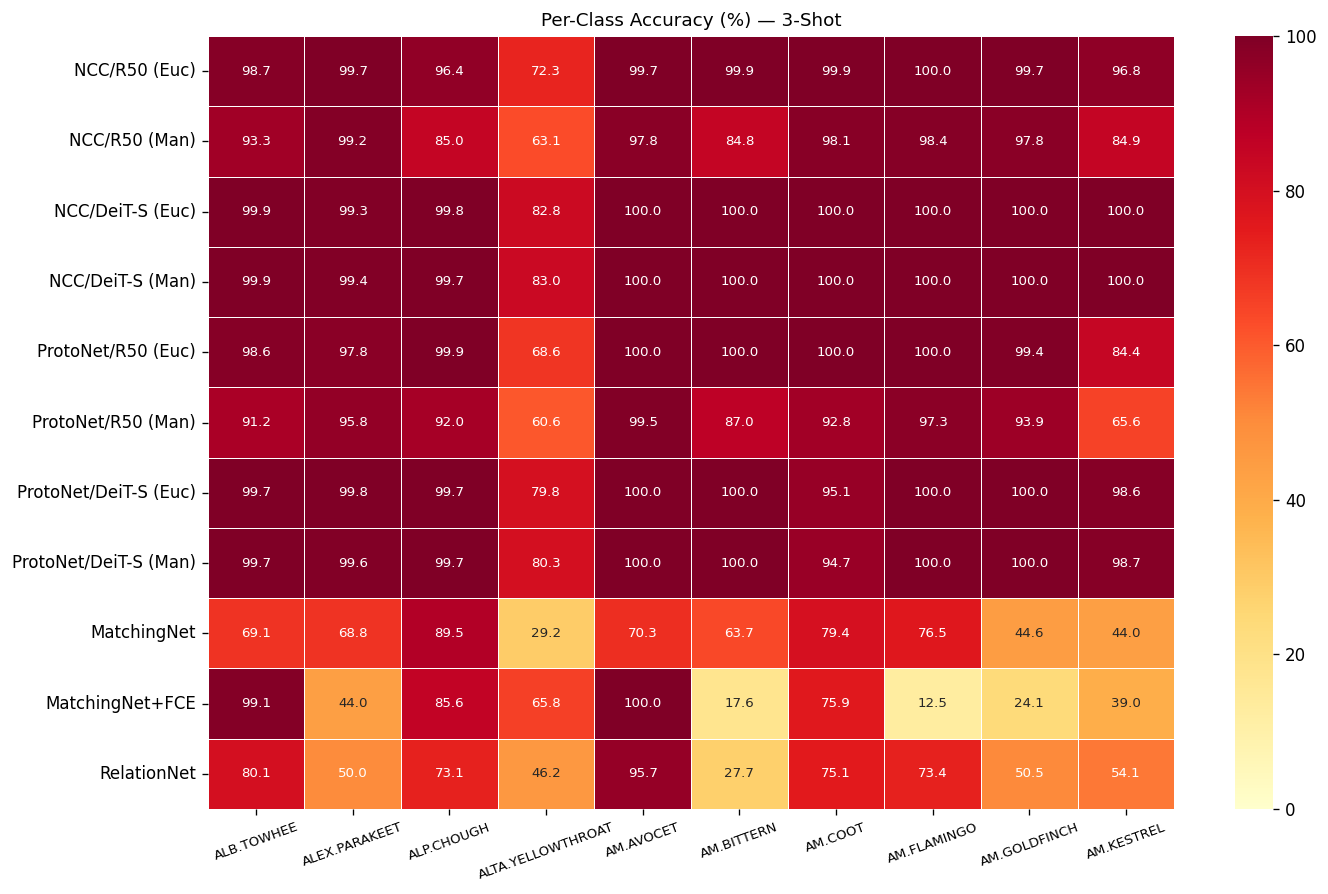

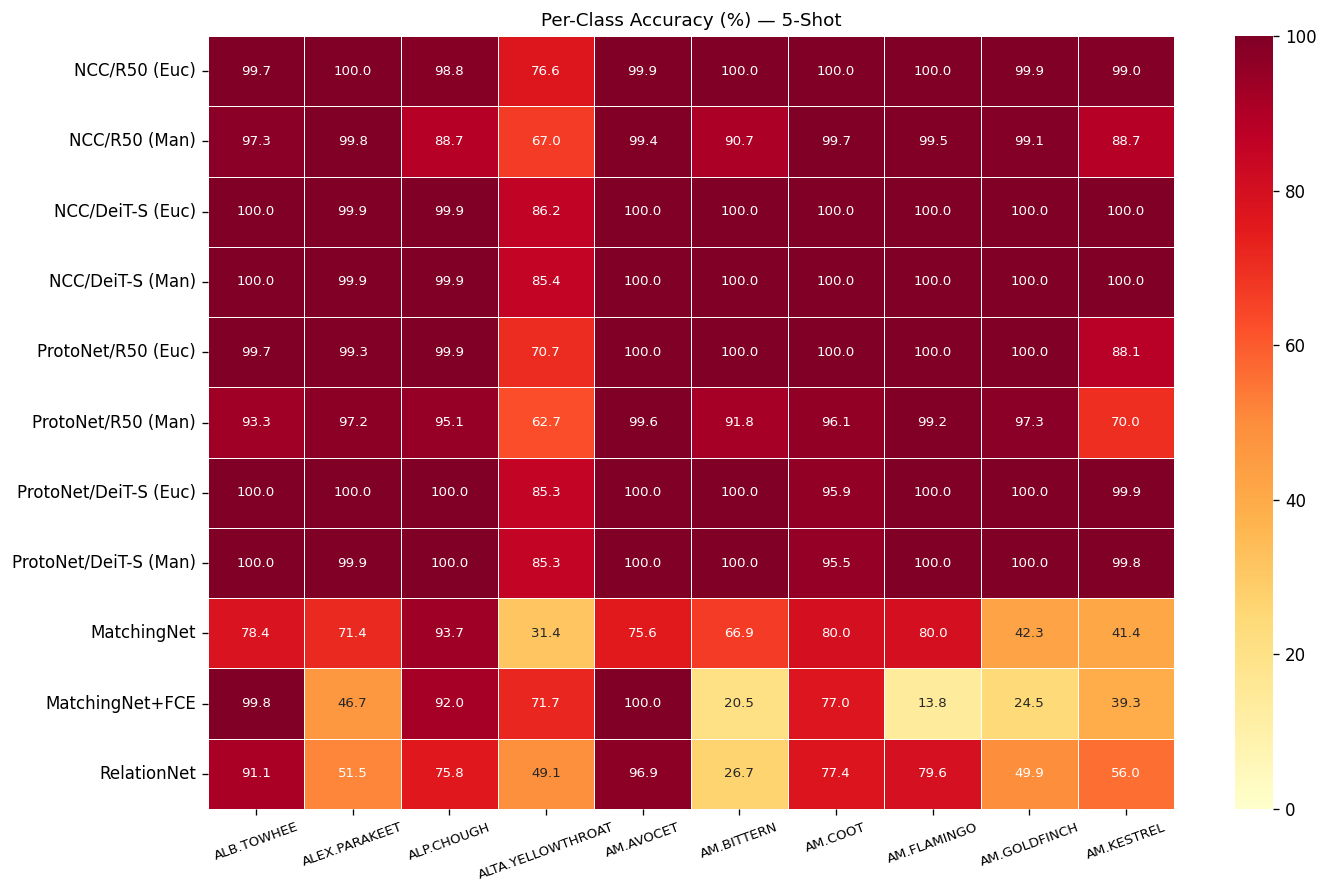

In [9]:

method_configs=[
    ('NCC/R50 (Euc)',         'ncc_{s}shot_euc_json',         '#fd8d3c','o','--'),
    ('NCC/R50 (Man)',         'ncc_{s}shot_man_json',         '#d94801','s',':'),
    ('NCC/DeiT-S (Euc)',      'vit_ncc_{s}shot_euc_json',     '#9467bd','o','--'),
    ('NCC/DeiT-S (Man)',      'vit_ncc_{s}shot_man_json',     '#c5b0d5','s',':'),
    ('ProtoNet/R50 (Euc)',    'proto_{s}shot_euc_json',       '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',    'proto_{s}shot_man_json',       '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json',   '#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json',   '#9edae5','s','-.'),
    ('MatchingNet',           'match_{s}shot_json',           '#2ca02c','^','-'),
    ('MatchingNet+FCE',       'match_fce_{s}shot_json',       '#98df8a','^','--'),
    ('RelationNet',           'rel_{s}shot_json',             '#d62728','D','--'),
]

for shot in SHOTS:
    defs=[(label,R.get(tmpl.format(s=shot))) for label,tmpl,*_ in method_configs]
    matrix,row_labels,any_data=[],[],False
    for name,d in defs:
        if d and 'per_class_accuracy_pct' in d:
            pca=d['per_class_accuracy_pct']
            matrix.append([pca.get(c,float('nan')) for c in NOVEL]); any_data=True
        else: matrix.append([float('nan')]*len(NOVEL))
        row_labels.append(name)
    if not any_data: continue
    matrix=np.array(matrix,dtype=float)
    fig,ax=plt.subplots(figsize=(max(10,len(NOVEL)*1.2),len(method_configs)*0.55+1.5))
    sns.heatmap(matrix,annot=True,fmt='.1f',cmap='YlOrRd',
                xticklabels=SHORT,yticklabels=row_labels,
                ax=ax,vmin=0,vmax=100,linewidths=0.5,linecolor='white',
                annot_kws={'size':8},mask=np.isnan(matrix))
    ax.set_title(f'Per-Class Accuracy (%) — {shot}-Shot',fontsize=11)
    ax.tick_params(axis='x',labelrotation=20,labelsize=8); ax.tick_params(axis='y',labelrotation=0)
    plt.tight_layout(); plt.show()


---
## 9. Hardest Novel Classes Analysis

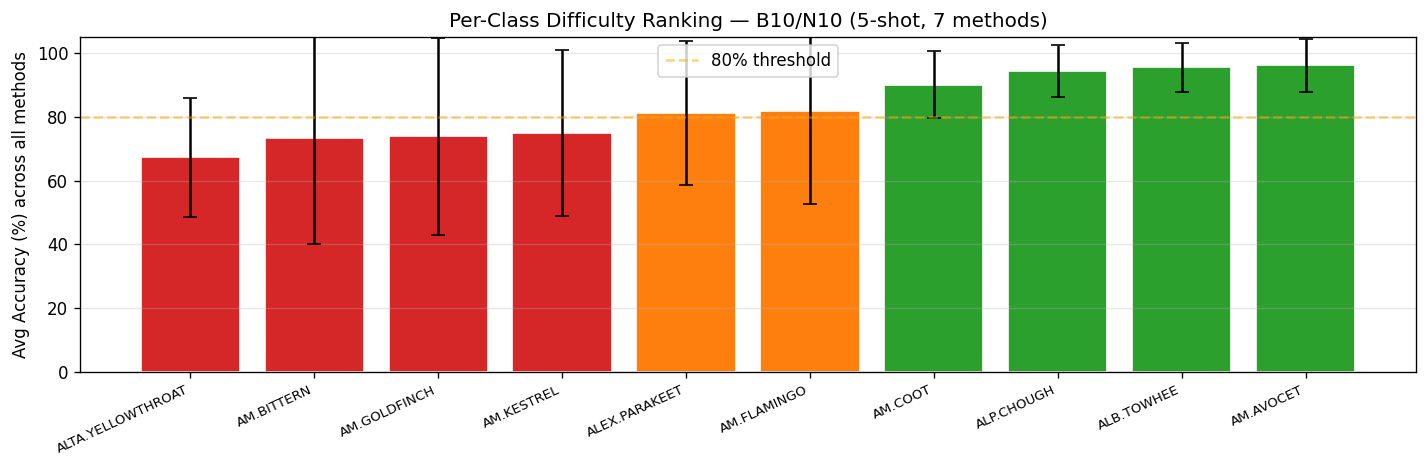

Hardest novel classes:
  ALTAMIRA YELLOWTHROAT: 67.3% avg
  AMERICAN BITTERN: 73.5% avg
  AMERICAN GOLDFINCH: 73.8% avg


In [10]:

# Average per-class accuracy across all methods at 5-shot euclidean
keys_5shot=['ncc_5shot_euc_json','vit_ncc_5shot_euc_json','proto_5shot_euc_json','vit_proto_5shot_euc_json',
             'match_5shot_json','match_fce_5shot_json','rel_5shot_json']
class_accs={c:[] for c in NOVEL}
for k in keys_5shot:
    d=R.get(k)
    if d and 'per_class_accuracy_pct' in d:
        for c in NOVEL: class_accs[c].append(d['per_class_accuracy_pct'].get(c,float('nan')))
avg_cls={c:np.nanmean(vs) for c,vs in class_accs.items() if vs}
std_cls={c:np.nanstd(vs) for c,vs in class_accs.items() if vs}

fig,ax=plt.subplots(figsize=(12,4))
sorted_cls=sorted(avg_cls.keys(),key=lambda c:avg_cls[c])
colors=['#d62728' if avg_cls[c]<80 else '#ff7f0e' if avg_cls[c]<90 else '#2ca02c' for c in sorted_cls]
x=np.arange(len(sorted_cls))
ax.bar(x,[avg_cls[c] for c in sorted_cls],color=colors,
        yerr=[std_cls[c] for c in sorted_cls],capsize=4,edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels([c.replace('AMERICAN ','AM.').replace('ALEXANDRINE ','ALEX.').replace('ALTAMIRA ','ALTA.').replace('ALBERTS ','ALB.').replace('ALPINE ','ALP.') for c in sorted_cls],rotation=25,ha='right',fontsize=8)
ax.set_ylabel('Avg Accuracy (%) across all methods'); ax.set_ylim(0,105)
ax.set_title('Per-Class Difficulty Ranking — B10/N10 (5-shot, 7 methods)')
ax.axhline(80,color='orange',linestyle='--',alpha=0.5,label='80% threshold')
ax.legend(); ax.grid(axis='y',alpha=0.3)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b10n10_class_difficulty.png',dpi=150); plt.show()
print('Hardest novel classes:')
for c in sorted_cls[:3]: print(f'  {c}: {avg_cls[c]:.1f}% avg')


---
## 10. Full Summary Table

In [11]:

rows=[]
methods=[
    ('NCC/R50 (Euc)','ncc_{s}shot_euc_json'),
    ('NCC/R50 (Man)','ncc_{s}shot_man_json'),
    ('NCC/DeiT-S (Euc)','vit_ncc_{s}shot_euc_json'),
    ('NCC/DeiT-S (Man)','vit_ncc_{s}shot_man_json'),
    ('ProtoNet/R50 (Euc)','proto_{s}shot_euc_json'),
    ('ProtoNet/R50 (Man)','proto_{s}shot_man_json'),
    ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json'),
    ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json'),
    ('MatchingNet','match_{s}shot_json'),
    ('MatchingNet+FCE','match_fce_{s}shot_json'),
    ('RelationNet','rel_{s}shot_json'),
]
for s in SHOTS:
    for label,tmpl in methods:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Method':label,'K-Shot':s,
                     'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—',
                     'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—',
                     'Precision':f"{float(d['macro_precision']):.4f}" if d and d.get('macro_precision') else '—',
                     'Recall':f"{float(d['macro_recall']):.4f}" if d and d.get('macro_recall') else '—',
                     'AUC':f"{float(d['auc_ovr']):.4f}" if d and d.get('auc_ovr') else '—'})
k='proto_5shot_euc_tta8_json'; d=R.get(k)
rows.append({'Method':'ProtoNet/R50+TTA8 (Euc)','K-Shot':5,
             'Accuracy(%)':f'{acc(k):.2f}' if d else '—','95% CI':f'+-{ci(k):.2f}' if d else '—',
             'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—',
             'Precision':f"{float(d['macro_precision']):.4f}" if d and d.get('macro_precision') else '—',
             'Recall':f"{float(d['macro_recall']):.4f}" if d and d.get('macro_recall') else '—',
             'AUC':f"{float(d['auc_ovr']):.4f}" if d and d.get('auc_ovr') else '—'})
df_s=pd.DataFrame(rows); df_s.index=range(1,len(df_s)+1)
display(df_s)
df_s.to_csv(f'{ANALYSIS}/b10n10_summary.csv')
print(f'Saved to {ANALYSIS}/b10n10_summary.csv')


,Method,K-Shot,Accuracy(%),95% CI,F1,Precision,Recall,AUC
1,NCC/R50 (Euc),1,87.01,+-0.81,0.8703,0.8758,0.8701,0.9780
2,NCC/R50 (Man),1,76.28,+-0.99,0.7654,0.7831,0.7628,0.9215
3,NCC/DeiT-S (Euc),1,95.35,+-0.49,0.9534,0.9549,0.9535,0.9972
4,NCC/DeiT-S (Man),1,95.42,+-0.48,0.9541,0.9555,0.9542,0.9932
5,ProtoNet/R50 (Euc),1,88.45,+-0.80,0.8842,0.8857,0.8845,0.9805
6,ProtoNet/R50 (Man),1,76.10,+-1.00,0.7626,0.7710,0.7610,0.9212
7,ProtoNet/DeiT-S (Euc),1,94.47,+-0.52,0.9447,0.9454,0.9447,0.9966
8,ProtoNet/DeiT-S (Man),1,94.40,+-0.50,0.9440,0.9447,0.9440,0.9933
9,MatchingNet,1,59.11,+-1.01,0.5920,0.5961,0.5911,0.8219
10,MatchingNet+FCE,1,53.99,+-1.03,0.5300,0.5575,0.5399,0.8442


Saved to .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results\analysis/b10n10_summary.csv


---
## 11. Key Insights (B10/N10)

In [12]:

print('='*70)
print('  KEY FINDINGS — B10/N10')
print('='*70)

for algo,r50t,vitr in [('NCC','ncc_{s}shot_euc_json','vit_ncc_{s}shot_euc_json'),
                        ('ProtoNet','proto_{s}shot_euc_json','vit_proto_{s}shot_euc_json')]:
    print(f'\n{algo} — DeiT-S vs R50 lift (Euclidean):')
    for s in SHOTS:
        r=acc(r50t.format(s=s)); v=acc(vitr.format(s=s))
        print(f'  {s}-shot: DeiT-S={v:.2f}%  R50={r:.2f}%  delta={v-r:+.2f}pp')

print('\nMatchingNet FCE effect (B10/N10):')
for s in SHOTS:
    v=acc(f'match_{s}shot_json'); fce=acc(f'match_fce_{s}shot_json')
    print(f'  {s}-shot: FCE={fce:.2f}%  vanilla={v:.2f}%  delta={fce-v:+.2f}pp')

print(f'\nTTA (5-shot Euc): {acc("proto_5shot_euc_tta8_json"):.2f}% vs {acc("proto_5shot_euc_json"):.2f}%  delta={acc("proto_5shot_euc_tta8_json")-acc("proto_5shot_euc_json"):+.2f}pp')

print('\nHardest novel class (lowest avg accuracy across all methods at 5-shot):')
class_accs={c:[] for c in NOVEL}
for k in ['ncc_5shot_euc_json','vit_ncc_5shot_euc_json','proto_5shot_euc_json','vit_proto_5shot_euc_json']:
    d=R.get(k)
    if d and 'per_class_accuracy_pct' in d:
        for c in NOVEL: class_accs[c].append(d['per_class_accuracy_pct'].get(c,float('nan')))
avg={c:np.nanmean(vs) for c,vs in class_accs.items() if vs}
for c,a in sorted(avg.items(),key=lambda x:x[1]):
    print(f'  {c}: {a:.1f}%')


  KEY FINDINGS — B10/N10

NCC — DeiT-S vs R50 lift (Euclidean):
  1-shot: DeiT-S=95.35%  R50=87.01%  delta=+8.34pp
  3-shot: DeiT-S=98.11%  R50=96.20%  delta=+1.91pp
  5-shot: DeiT-S=98.61%  R50=97.40%  delta=+1.21pp

ProtoNet — DeiT-S vs R50 lift (Euclidean):
  1-shot: DeiT-S=94.47%  R50=88.45%  delta=+6.01pp
  3-shot: DeiT-S=97.17%  R50=94.83%  delta=+2.35pp
  5-shot: DeiT-S=98.11%  R50=95.77%  delta=+2.35pp

MatchingNet FCE effect (B10/N10):
  1-shot: FCE=53.99%  vanilla=59.11%  delta=-5.11pp
  3-shot: FCE=56.85%  vanilla=63.35%  delta=-6.50pp
  5-shot: FCE=58.81%  vanilla=66.74%  delta=-7.93pp

TTA (5-shot Euc): 96.64% vs 95.77%  delta=+0.87pp

Hardest novel class (lowest avg accuracy across all methods at 5-shot):
  ALTAMIRA YELLOWTHROAT: 79.7%
  AMERICAN KESTREL: 96.7%
  AMERICAN COOT: 99.0%
  ALPINE CHOUGH: 99.7%
  ALEXANDRINE PARAKEET: 99.8%
  ALBERTS TOWHEE: 99.9%
  AMERICAN AVOCET: 100.0%
  AMERICAN GOLDFINCH: 100.0%
  AMERICAN BITTERN: 100.0%
  AMERICAN FLAMINGO: 100.0%
